# Dyslexia Classification via Hybrid Deep Learning Models

# Install Libraries

In [1]:
!pip install imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 91.8 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-learn-1.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
category-encoders 2.7.0 requires scikit-learn<1.6.0,>=1.0.0, but you have scikit-learn 1.6.1 which is incompatible.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incompatible.


# Import Libraries

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from scipy.stats import mode
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler

E0000 00:00:1759730475.861275      13 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1759730475.937124      13 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


# Load Dataset

In [3]:
df = pd.read_csv('/kaggle/input/dyslexia/Dyt-desktop.csv', delimiter=';')

# Read Dataset

In [4]:
df

,Gender,Nativelang,Otherlang,Age,Clicks1,Hits1,Misses1,Score1,Accuracy1,Missrate1,...,Score31,Accuracy31,Missrate31,Clicks32,Hits32,Misses32,Score32,Accuracy32,Missrate32,Dyslexia
0,Male,No,Yes,7,10,10,0,10,1.0,0.0,...,0,0.000000,0.00,17,2,0,2,0.117647,0.000000,No
1,Female,Yes,Yes,13,12,12,0,12,1.0,0.0,...,4,0.114286,0.00,26,2,2,2,0.076923,0.076923,Yes
2,Female,No,Yes,7,6,6,0,6,1.0,0.0,...,4,0.114286,0.00,26,1,3,1,0.038462,0.115385,No
3,Female,No,Yes,7,0,0,0,0,0.0,0.0,...,0,0.000000,0.00,1,0,0,0,0.000000,0.000000,No
4,Female,No,Yes,8,4,4,0,4,1.0,0.0,...,1,25.000000,0.05,26,2,2,2,0.076923,0.076923,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3639,Male,No,No,10,7,7,0,7,1.0,0.0,...,2,0.670000,0.33,4,1,3,1,0.250000,0.750000,Yes
3640,Female,No,Yes,15,9,9,0,9,1.0,0.0,...,3,0.750000,0.25,4,2,2,2,0.500000,0.500000,No
3641,Female,No,Yes,15,11,11,0,11,1.0,0.0,...,3,0.600000,0.40,4,2,2,2,0.500000,0.500000,No
3642,Female,No,Yes,15,10,10,0,10,1.0,0.0,...,3,0.750000,0.25,4,3,1,3,0.750000,0.250000,No


In [5]:
print(list(df.columns))

['Gender', 'Nativelang', 'Otherlang', 'Age', 'Clicks1', 'Hits1', 'Misses1', 'Score1', 'Accuracy1', 'Missrate1', 'Clicks2', 'Hits2', 'Misses2', 'Score2', 'Accuracy2', 'Missrate2', 'Clicks3', 'Hits3', 'Misses3', 'Score3', 'Accuracy3', 'Missrate3', 'Clicks4', 'Hits4', 'Misses4', 'Score4', 'Accuracy4', 'Missrate4', 'Clicks5', 'Hits5', 'Misses5', 'Score5', 'Accuracy5', 'Missrate5', 'Clicks6', 'Hits6', 'Misses6', 'Score6', 'Accuracy6', 'Missrate6', 'Clicks7', 'Hits7', 'Misses7', 'Score7', 'Accuracy7', 'Missrate7', 'Clicks8', 'Hits8', 'Misses8', 'Score8', 'Accuracy8', 'Missrate8', 'Clicks9', 'Hits9', 'Misses9', 'Score9', 'Accuracy9', 'Missrate9', 'Clicks10', 'Hits10', 'Misses10', 'Score10', 'Accuracy10', 'Missrate10', 'Clicks11', 'Hits11', 'Misses11', 'Score11', 'Accuracy11', 'Missrate11', 'Clicks12', 'Hits12', 'Misses12', 'Score12', 'Accuracy12', 'Missrate12', 'Clicks13', 'Hits13', 'Misses13', 'Score13', 'Accuracy13', 'Missrate13', 'Clicks14', 'Hits14', 'Misses14', 'Score14', 'Accuracy14', '

# Feature Variance Plot

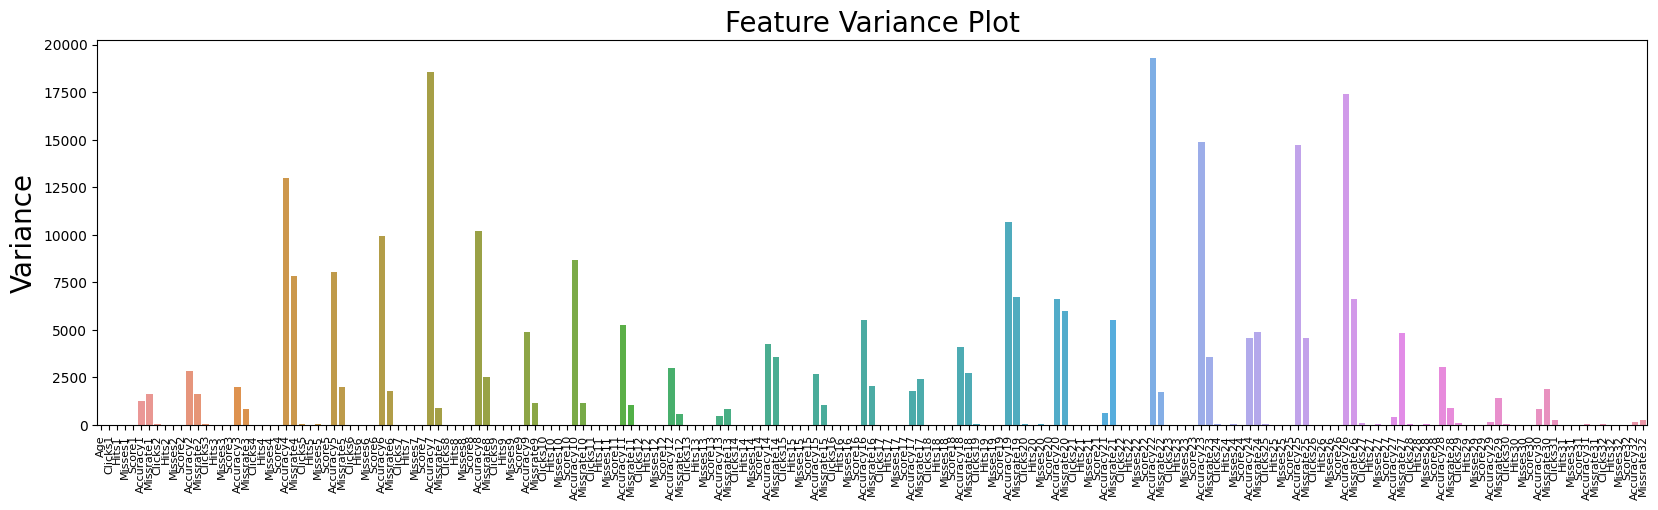

In [6]:
from sklearn.feature_selection import VarianceThreshold
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numeric columns
numeric_df = df.select_dtypes(include='number')

# Apply Variance Threshold
selector = VarianceThreshold(threshold=0.1)
selector.fit(numeric_df)
variances = selector.variances_

# Plot
plt.figure(figsize=(20, 5))
sns.barplot(x=numeric_df.columns, y=variances)
plt.xticks(rotation=90, fontsize=8)  # Adjust fontsize here
plt.ylabel("Variance",fontsize='20')
plt.title("Feature Variance Plot",fontsize='20')
plt.show()


# Preprocessing

In [7]:
import numpy as np
import pandas as pd

class Preprocessing:
    def __init__(self, df):
        self.df = df
        self.df_clean = df.copy()

    def preprocess(self):
        # Impute missing values for numeric columns with the median value
        numeric_cols = self.df_clean.select_dtypes(include=[np.number]).columns
        for col in numeric_cols:
            median_val = self.df_clean[col].median()
            self.df_clean[col] = self.df_clean[col].fillna(median_val)

        # Impute missing values for categorical columns with the mode value
        categorical_cols = self.df_clean.select_dtypes(include=['object', 'category']).columns
        for col in categorical_cols:
            if not self.df_clean[col].mode().empty:
                mode_val = self.df_clean[col].mode().iloc[0]
                self.df_clean[col] = self.df_clean[col].fillna(mode_val)
            else:
                self.df_clean[col] = self.df_clean[col].fillna("Unknown")

        return self.df_clean

# Example usage:
# Suppose 'df' is your original DataFrame that you want to preprocess.
processor = Preprocessing(df)
df_clean = processor.preprocess()

# The final line prints the df_clean DataFrame as output in the notebook.
df_clean


,Gender,Nativelang,Otherlang,Age,Clicks1,Hits1,Misses1,Score1,Accuracy1,Missrate1,...,Score31,Accuracy31,Missrate31,Clicks32,Hits32,Misses32,Score32,Accuracy32,Missrate32,Dyslexia
0,Male,No,Yes,7,10,10,0,10,1.0,0.0,...,0,0.000000,0.00,17,2,0,2,0.117647,0.000000,No
1,Female,Yes,Yes,13,12,12,0,12,1.0,0.0,...,4,0.114286,0.00,26,2,2,2,0.076923,0.076923,Yes
2,Female,No,Yes,7,6,6,0,6,1.0,0.0,...,4,0.114286,0.00,26,1,3,1,0.038462,0.115385,No
3,Female,No,Yes,7,0,0,0,0,0.0,0.0,...,0,0.000000,0.00,1,0,0,0,0.000000,0.000000,No
4,Female,No,Yes,8,4,4,0,4,1.0,0.0,...,1,25.000000,0.05,26,2,2,2,0.076923,0.076923,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3639,Male,No,No,10,7,7,0,7,1.0,0.0,...,2,0.670000,0.33,4,1,3,1,0.250000,0.750000,Yes
3640,Female,No,Yes,15,9,9,0,9,1.0,0.0,...,3,0.750000,0.25,4,2,2,2,0.500000,0.500000,No
3641,Female,No,Yes,15,11,11,0,11,1.0,0.0,...,3,0.600000,0.40,4,2,2,2,0.500000,0.500000,No
3642,Female,No,Yes,15,10,10,0,10,1.0,0.0,...,3,0.750000,0.25,4,3,1,3,0.750000,0.250000,No


# Feature selection

In [8]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import LabelEncoder

np.random.seed(42)
# ----- Step 1: Data Encoding ----- #
df_encoded = df_clean.copy()

# Specify your target column
target_column = 'Dyslexia'
if target_column not in df_encoded.columns:
    target_column = df_encoded.columns[-1]  

# Convert target column to numeric if it is categorical
if df_encoded[target_column].dtype == 'object':
    # For binary categorical target, map directly; else use LabelEncoder
    unique_vals = df_encoded[target_column].unique()
    if len(unique_vals) == 2:
        mapping = {val: idx for idx, val in enumerate(unique_vals)}
        df_encoded[target_column] = df_encoded[target_column].map(mapping)
    else:
        le = LabelEncoder()
        df_encoded[target_column] = le.fit_transform(df_encoded[target_column])

# Separate features and target
X = df_encoded.drop(columns=[target_column])
y = df_encoded[target_column].values

# One-hot encode categorical features for X, if any are detected
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
if len(categorical_cols) > 0:
    X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Convert X to a NumPy array
X_np = X.values

print("Encoded feature matrix shape:", X_np.shape)
print("Target variable shape:", y.shape)


# ----- Step 2: EEFOA for Feature Selection ----- #
class EEFOA:
    def __init__(self, n_features, n_pop=30, max_iter=10):
        self.n_features = n_features
        self.n_pop = n_pop
        self.max_iter = max_iter

    def initialize_population(self):
        population = np.random.randint(2, size=(self.n_pop, self.n_features))
        return population

    def fitness(self, solution, X, y):
        if np.sum(solution) == 0:
            return 0
        selected_features = np.where(solution == 1)[0]
        X_selected = X[:, selected_features]

        model = RandomForestClassifier(n_estimators=10, random_state=42)
        # Evaluate using 5-fold cross-validation
        score = np.mean(cross_val_score(model, X_selected, y, cv=5, scoring='accuracy'))

        # Penalize for selecting too many features
        penalty = np.sum(solution) / self.n_features
        return score - 0.01 * penalty

    def update_solution(self, solution, best_solution):
        new_solution = solution.copy()
        for i in range(len(solution)):
            if np.random.rand() < 0.5:
                new_solution[i] = best_solution[i]  # Exploit: copy from best solution
            else:
                # Explore: flip the bit with a small probability
                if np.random.rand() < 0.1:
                    new_solution[i] = 1 - new_solution[i]
        return new_solution

    def run(self, X, y):
        population = self.initialize_population()
        best_solution = population[0].copy()
        best_fitness = -np.inf

        for iteration in range(self.max_iter):
            new_population = []
            for sol in population:
                new_sol = self.update_solution(sol, best_solution)
                new_population.append(new_sol)
            population = np.array(new_population)

            # Update best solution by evaluating all candidates
            for sol in population:
                sol_fitness = self.fitness(sol, X, y)
                if sol_fitness > best_fitness:
                    best_fitness = sol_fitness
                    best_solution = sol.copy()

            print(f"Iteration {iteration+1}/{self.max_iter} -- Best fitness: {best_fitness:.4f}")

        return best_solution

# ----- Step 3: Run Feature Selection with EEFOA ----- #
n_features = X_np.shape[1]
eefoa_selector = EEFOA(n_features=n_features, n_pop=30, max_iter=10)

# Run the optimization to get the best feature subset mask
best_feature_mask = eefoa_selector.run(X_np, y)
selected_feature_indices = np.where(best_feature_mask == 1)[0]
print("\nSelected Feature Indices:", selected_feature_indices)

# Optional: Create a DataFrame with only the selected features plus the target column
selected_features = X.columns[selected_feature_indices]
df_selected = pd.concat([
    pd.DataFrame(X_np[:, selected_feature_indices], columns=selected_features),
    pd.DataFrame(y, columns=[target_column])
], axis=1)

df_selected.head()


Encoded feature matrix shape: (3644, 196)
Target variable shape: (3644,)
Iteration 1/10 -- Best fitness: 0.8901
Iteration 2/10 -- Best fitness: 0.8911
Iteration 3/10 -- Best fitness: 0.8920
Iteration 4/10 -- Best fitness: 0.8927
Iteration 5/10 -- Best fitness: 0.8927
Iteration 6/10 -- Best fitness: 0.8927
Iteration 7/10 -- Best fitness: 0.8927
Iteration 8/10 -- Best fitness: 0.8927
Iteration 9/10 -- Best fitness: 0.8927
Iteration 10/10 -- Best fitness: 0.8927

Selected Feature Indices: [  0   2   8   9  12  14  17  18  19  23  24  27  29  30  32  33  36  40
  42  43  46  48  49  51  53  56  62  64  67  68  69  70  71  75  76  78
  79  81  89  90  91  95  96  97  99 100 102 104 105 106 108 110 111 113
 115 116 122 125 128 129 130 132 133 135 137 138 140 143 144 149 153 155
 158 159 162 164 165 168 169 170 171 172 173 176 180 181 182 185 186 189
 192 194]


,Age,Hits1,Hits2,Misses2,Missrate2,Hits3,Accuracy3,Missrate3,Clicks4,Accuracy4,...,Hits30,Missrate30,Clicks31,Hits31,Accuracy31,Missrate31,Misses32,Missrate32,Nativelang_Yes,Dyslexia
0,7,10,5,0,0.0,6,1.0,0.0,2,1.0,...,1,0.142857,18,0,0.0,0.0,0,0.0,False,0
1,13,12,11,0,0.0,10,1.0,0.0,4,1.0,...,2,0.117647,35,4,0.114286,0.0,2,0.076923,True,1
2,7,6,6,0,0.0,6,1.0,0.0,3,1.0,...,1,0.176471,35,4,0.114286,0.0,3,0.115385,False,0
3,7,0,0,0,0.0,1,1.0,0.0,0,0.0,...,0,125.0,4,0,0.0,0.0,0,0.0,False,0
4,8,4,8,0,0.0,5,1.0,0.0,5,0.4,...,0,0.235294,40,1,25.0,0.05,2,0.076923,False,0


In [9]:
# print names and count
print(f"Number of selected features: {len(selected_features)}")
print("Selected features:", list(selected_features))

Number of selected features: 92
Selected features: ['Age', 'Hits1', 'Hits2', 'Misses2', 'Missrate2', 'Hits3', 'Accuracy3', 'Missrate3', 'Clicks4', 'Accuracy4', 'Missrate4', 'Misses5', 'Accuracy5', 'Missrate5', 'Hits6', 'Misses6', 'Missrate6', 'Score7', 'Missrate7', 'Clicks8', 'Score8', 'Missrate8', 'Clicks9', 'Misses9', 'Accuracy9', 'Hits10', 'Hits11', 'Score11', 'Clicks12', 'Hits12', 'Misses12', 'Score12', 'Accuracy12', 'Misses13', 'Score13', 'Missrate13', 'Clicks14', 'Misses14', 'Accuracy15', 'Missrate15', 'Clicks16', 'Accuracy16', 'Missrate16', 'Clicks17', 'Misses17', 'Score17', 'Missrate17', 'Hits18', 'Misses18', 'Score18', 'Missrate18', 'Hits19', 'Misses19', 'Accuracy19', 'Clicks20', 'Hits20', 'Hits21', 'Accuracy21', 'Hits22', 'Misses22', 'Score22', 'Missrate22', 'Clicks23', 'Misses23', 'Accuracy23', 'Missrate23', 'Hits24', 'Accuracy24', 'Missrate24', 'Accuracy25', 'Misses26', 'Accuracy26', 'Hits27', 'Misses27', 'Missrate27', 'Hits28', 'Misses28', 'Missrate28', 'Clicks29', 'Hits29

# Build Model - DFNN

In [10]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# === Split Features and Label ===
X = df_selected.drop(columns='Dyslexia')
y = df_selected['Dyslexia']
print("Unique y values before encoding:", y.unique())

# Convert 'Yes' → 1, 'No' → 0
le = LabelEncoder()
y = le.fit_transform(y)  # y now contains binary values (0 or 1)

print("Data types of features:", dict(X.dtypes))

# === Scale Features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# === Oversample using SMOTE ===
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)

# Convert to proper data types for Keras
X_res = X_res.astype(np.float32)
y_res = y_res.astype(np.int32)

# === Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# ========== DFNN Model Class ==========
class DFNN:
    def __init__(self, input_dim):
        self.input_dim = input_dim
        self.model = None
        self.build_model()

    def build_model(self):
        self.model = Sequential([
            # Use an explicit Input layer here
            Input(shape=(self.input_dim,)),
            Dense(512, activation='relu'),
            Dropout(0.4),
            Dense(256, activation='relu'),
            Dropout(0.4),
            Dense(128, activation='relu'),
            Dropout(0.3),
            Dense(64, activation='relu'),
            Dense(1, activation='sigmoid')
        ])
        self.model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
        return self.model

    def train(self, X_train, y_train, validation_split=0.2, epochs=50, batch_size=32):
        """Trains the model using early stopping based on validation loss."""
        early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
        self.history = self.model.fit(
            X_train, y_train,
            validation_split=validation_split,
            epochs=epochs,
            batch_size=batch_size,
            callbacks=[early_stop],
            verbose=1
        )

    def evaluate(self, X_test, y_test):
        """Evaluates the model on the provided test set."""
        return self.model.evaluate(X_test, y_test)

    def predict(self, X_new):
        """Makes predictions on new data."""
        return self.model.predict(X_new)

# ========== Instantiating and Using the DFNN Class ==========
dfnn_model = DFNN(input_dim=X_train.shape[1])


Unique y values before encoding: [0 1]
Data types of features: {'Age': dtype('O'), 'Hits1': dtype('O'), 'Hits2': dtype('O'), 'Misses2': dtype('O'), 'Missrate2': dtype('O'), 'Hits3': dtype('O'), 'Accuracy3': dtype('O'), 'Missrate3': dtype('O'), 'Clicks4': dtype('O'), 'Accuracy4': dtype('O'), 'Missrate4': dtype('O'), 'Misses5': dtype('O'), 'Accuracy5': dtype('O'), 'Missrate5': dtype('O'), 'Hits6': dtype('O'), 'Misses6': dtype('O'), 'Missrate6': dtype('O'), 'Score7': dtype('O'), 'Missrate7': dtype('O'), 'Clicks8': dtype('O'), 'Score8': dtype('O'), 'Missrate8': dtype('O'), 'Clicks9': dtype('O'), 'Misses9': dtype('O'), 'Accuracy9': dtype('O'), 'Hits10': dtype('O'), 'Hits11': dtype('O'), 'Score11': dtype('O'), 'Clicks12': dtype('O'), 'Hits12': dtype('O'), 'Misses12': dtype('O'), 'Score12': dtype('O'), 'Accuracy12': dtype('O'), 'Misses13': dtype('O'), 'Score13': dtype('O'), 'Missrate13': dtype('O'), 'Clicks14': dtype('O'), 'Misses14': dtype('O'), 'Accuracy15': dtype('O'), 'Missrate15': dtype(

# Train Model

In [11]:
# Train the model
dfnn_model.train(X_train, y_train, validation_split=0.2, epochs=30, batch_size=32)

# Evaluate the model performance
evaluation_results = dfnn_model.evaluate(X_test, y_test)

Epoch 1/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7022 - loss: 0.5676 - val_accuracy: 0.8415 - val_loss: 0.3683
Epoch 2/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8435 - loss: 0.3791 - val_accuracy: 0.8742 - val_loss: 0.3147
Epoch 3/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8810 - loss: 0.3085 - val_accuracy: 0.8924 - val_loss: 0.2834
Epoch 4/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9078 - loss: 0.2422 - val_accuracy: 0.9030 - val_loss: 0.2511
Epoch 5/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9238 - loss: 0.2105 - val_accuracy: 0.9203 - val_loss: 0.2148
Epoch 6/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9227 - loss: 0.2121 - val_accuracy: 0.9174 - val_loss: 0.2154
Epoch 7/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9267 - loss: 0.1932 - val_accuracy: 0.9251 - val_loss: 0.2271
Epoch 8/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9437 - loss: 0.1480 - val_accuracy: 0.

# Training History

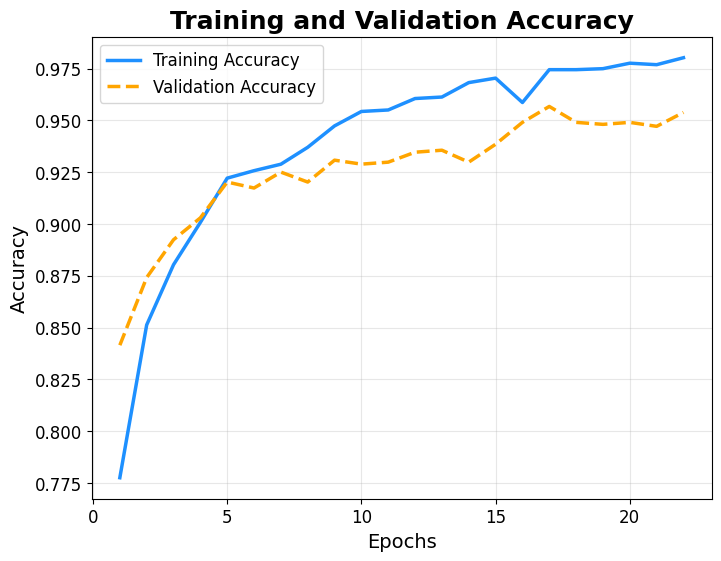

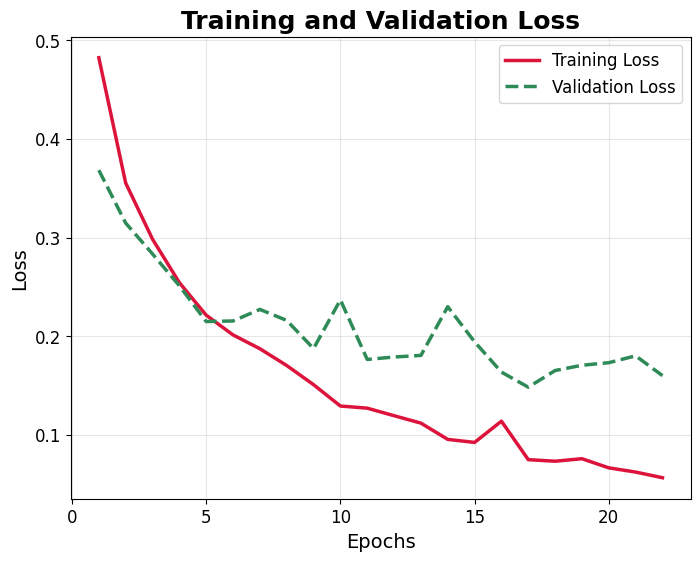

In [12]:
import matplotlib.pyplot as plt

# Extract training history
history = dfnn_model.history
epochs = range(1, len(history.history['accuracy']) + 1)

# ------------------------------
# Plot Training and Validation Accuracy
# ------------------------------
plt.figure(figsize=(8, 6))
plt.plot(epochs, history.history['accuracy'], color='dodgerblue', linewidth=2.5, label='Training Accuracy')
plt.plot(epochs, history.history['val_accuracy'], color='orange', linewidth=2.5, linestyle='--', label='Validation Accuracy')
plt.title("Training and Validation Accuracy", fontsize=18, fontweight='bold')
plt.xlabel("Epochs", fontsize=14)
plt.ylabel("Accuracy", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.show()

# ------------------------------
# Plot Training and Validation Loss
# ------------------------------
plt.figure(figsize=(8, 6))
plt.plot(epochs, history.history['loss'], color='crimson', linewidth=2.5, label='Training Loss')
plt.plot(epochs, history.history['val_loss'], color='seagreen', linewidth=2.5, linestyle='--', label='Validation Loss')
plt.title("Training and Validation Loss", fontsize=18, fontweight='bold')
plt.xlabel("Epochs", fontsize=14)
plt.ylabel("Loss", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.show()


# Confusion matrix

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


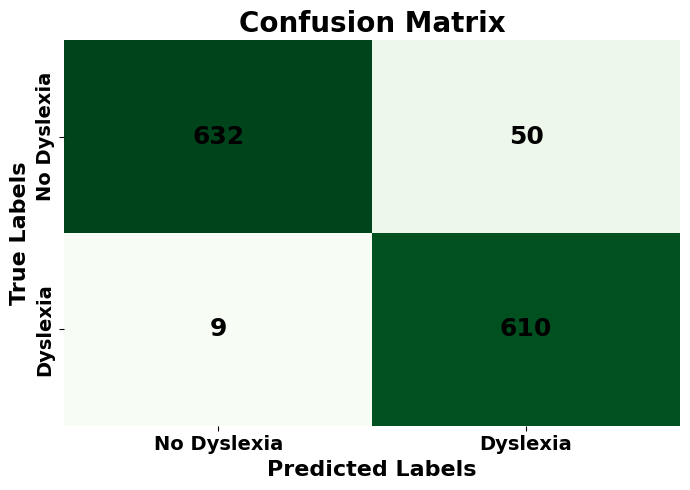

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Predict labels from the model
y_pred = (dfnn_model.predict(X_test) > 0.5).astype(int)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Define class names
class_names = ['No Dyslexia', 'Dyslexia']  # 0: No Dyslexia, 1: Dyslexia

# Plot the confusion matrix with enhanced styling
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    cbar=False,
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 18, "weight": "bold", "color": "black"}  # inside number style
)

# Titles and labels — bold & larger
plt.title("Confusion Matrix", fontsize=20, fontweight='bold')
plt.xlabel("Predicted Labels", fontsize=16, fontweight='bold')
plt.ylabel("True Labels", fontsize=16, fontweight='bold')

# Make tick labels bold and larger
plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')

# Improve layout
plt.tight_layout()
plt.show()


# Performance Metrics

In [14]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)
# Ensure the confusion matrix is 2x2 and unpack the values:
TN, FP, FN, TP = cm.ravel()

# Calculate performance metrics
accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
sensitivity = TP / (TP + FN) if (TP + FN) > 0 else 0  # Recall
specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
error_rate = 1 - accuracy

# Print metrics

print("====================")
print("Performance Metrics ")
print("====================")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Sensitivity : {sensitivity:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"Error Rate  : {error_rate:.4f}")


Performance Metrics 
Accuracy    : 0.9547
Precision   : 0.9242
Sensitivity : 0.9855
Specificity : 0.9267
Error Rate  : 0.0453
